# Preprocessing of COVID data

## Environment Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Parameters

In [93]:
raw_data_dir = Path("../../data/raw")
proc_data_dir = Path("../../data/processed")
ba_dir = raw_data_dir / "business-activity-trends-during-covid-19-20200301-20221129"

## Import Data

### Food prices

<Axes: xlabel='date'>

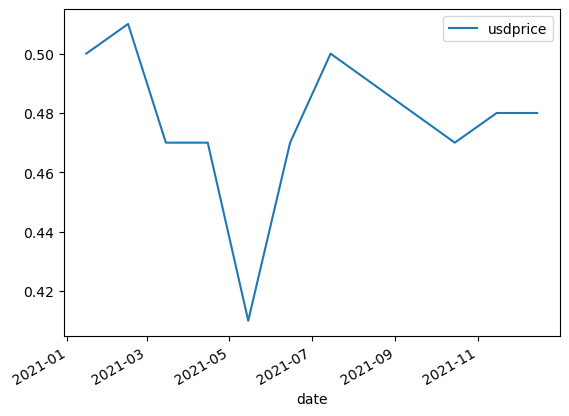

In [ ]:
fp_2021 = (
    pd.read_csv(
        raw_data_dir / "wfp_food_prices_global_2021.csv",
        parse_dates=["date"],
        skiprows=[1],
    )
    .loc[lambda x: (
        (x["countryiso3"] == "COD")
        & (x["admin1"] == "Sud-Kivu")
        & (x["category"] == "cereals and tubers")
        & (x["commodity"] == "Cassava flour")
    )]
    [[
        "date",
        "usdprice"
    ]]
)
fp_2021.set_index("date").plot()

### Business Activity

In [7]:
df_list = []
for f in ba_dir.glob("*.csv"):
    df = (
        pd.read_csv(f)
        .loc[lambda x: (
            (x["gadm_id"] == "COD")
            & (x["business_vertical"].isin(["Grocery & Convenience Stores", "Public Good"]))
        )]
        [["ds", "business_vertical", "activity_quantile"]]
    )
    df_list.append(df)

df_ba = (
    pd.concat(df_list, ignore_index=True)
    .sort_values(by=["ds", "business_vertical"])
    .reset_index(drop=True)
)


<Axes: xlabel='ds'>

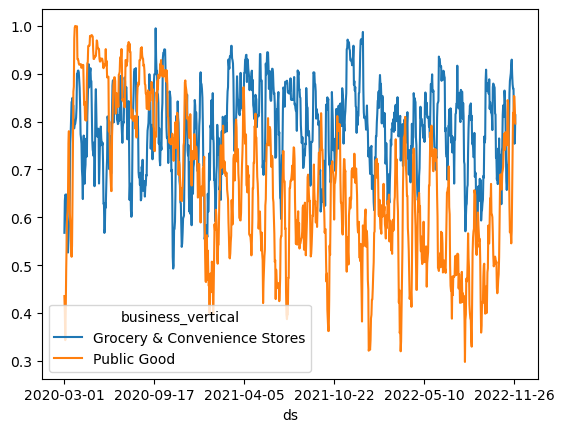

In [8]:
(
    df_ba
    .set_index("ds")
    .pivot(columns="business_vertical", values="activity_quantile")
    .plot()
)

### COVID Subnational Cases

In [ ]:
df_covid_sub_1 = (
    pd.read_csv(
        raw_data_dir / "Congo DRC COVID-19 Subnational cases - Sheet1.csv",
        skiprows=[1],
        parse_dates=["Date"],
    )
    .rename(columns=str.lower)
    .loc[lambda x: x["province"] == "Sud-Kivu"]
    .sort_values(by="date")
    .assign(
        cases = lambda x: x["confirmed cases"].diff().fillna(0).astype(int).clip(lower=0),
    )
    [[
        "date",
        "cases",
    ]]
)

In [50]:
df_covid_sub_1.head(20)

,date,cases
1002,2020-04-06,0
997,2020-04-07,0
992,2020-04-08,0
987,2020-04-12,0
982,2020-04-15,0
977,2020-04-17,0
972,2020-04-20,0
967,2020-04-22,0
962,2020-04-26,0
956,2020-04-27,0


In [ ]:
df_covid_sub_2 = (
    pd.read_csv(
        raw_data_dir / "drc_subnational_covid19_hera.csv",
        sep = ";",
        parse_dates=["DATE"],
    )
    .rename(columns=str.lower)
    .loc[lambda x: (
        (x["region"] == "Sud Kivu")
    )]
    [[
        "date",
        "contamines",
        # "deces",
        # "gueris",
    ]]
    .rename(columns={
        "contamines": "cases",
        # "deces": "deaths",
        # "gueris": "recovered",
    })
)

/var/folders/t5/wdgbs_cn20j1h277s6rs9ckw0000gp/T/ipykernel_70071/114800613.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  pd.read_csv(


In [91]:
df_covid_sub_2.head()

,date,cases
21,2020-09-19,303
48,2020-09-20,0
75,2020-09-21,0
102,2020-09-22,0
129,2020-09-23,0


In [81]:
df_covid_sub = (
    pd.concat(
        [df_covid_sub_1, df_covid_sub_2],
        ignore_index=True,
    )
    .sort_values(by="date")
    .reset_index(drop=True)
    .loc[lambda x: x["date"] >= "2020-03-01"]
    .groupby(pd.Grouper(key="date", freq="7D"))
    .agg(
        cases=("cases", "sum"),
    )
    .reset_index()
)

In [82]:
df_covid_sub.head()

,date,cases
0,2020-04-06,0
1,2020-04-13,0
2,2020-04-20,0
3,2020-04-27,0
4,2020-05-04,0


<Axes: xlabel='date'>

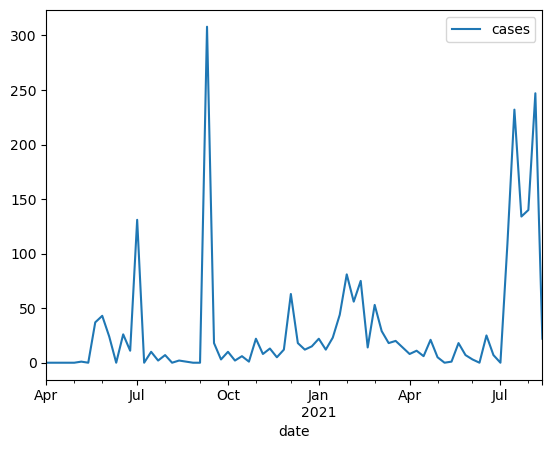

In [83]:
df_covid_sub.set_index("date").plot()

### COVID National Cases

In [ ]:
df_covid = (
    pd.read_csv(
        raw_data_dir / "daily-new-confirmed-covid-19-cases-per-million-people.csv",
        parse_dates=["Day"]
    )
    .rename(columns=str.lower)
    .rename(columns={
        "day": "date",
        "daily new confirmed cases of covid-19 per million people": "new_cases_per_million",
    })
    .loc[lambda x: x["date"] >= "2020-03-01"]
    .groupby(pd.Grouper(key="date", freq="7D"))
    .agg(
        weekly_cases_per_million=("new_cases_per_million", "sum"),
    )
    .reset_index()
    [["date", "weekly_cases_per_million"]]
)

<Axes: xlabel='date'>

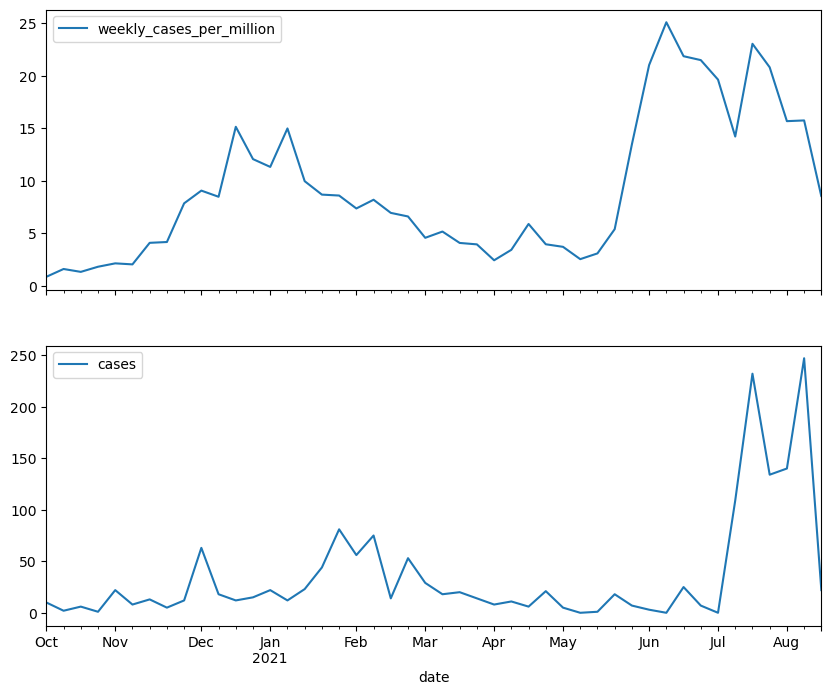

In [92]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
(
    df_covid
    .loc[lambda x: (
        (x["date"] >= "2020-10-01")
        & (x["date"] <= "2021-09-01")
    )]
    .set_index("date")
    .plot(ax = axes[0])
)
(
    df_covid_sub
    .loc[lambda x: (
        (x["date"] >= "2020-10-01")
        & (x["date"] <= "2021-09-01")
    )]
    .set_index("date")
    .plot(ax = axes[1])
)

## Save Data

In [94]:
df_covid.to_csv(proc_data_dir / "drc_covid_cases_per_million.csv", index=False)